# TP 2: Simple neural networks

## Part 1: Implement your own Multi-Layer Perceptron (MLP) and vanilla Convolutional Neural Network (CNN) on FashionMNIST data

Help:
- https://pytorch.org/tutorials/beginner/basics/intro.html
- https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html

### 1. Load useful packages

Some of the modules will be imported only when required. But obviously, it is clearer to put these imports at the beginning of your scripts.

In [1]:
import scipy # scientific computing library
import numpy as np # manipulate N-dimensional arrays
import pandas as pd # data frame
import matplotlib.pyplot as plt # data plotting
import seaborn # advanced data plotting
from sklearn import preprocessing # basic ML models

import os

import torch

Check the version of Pytorch

In [2]:
torch.__version__

'2.14.0+cu130'

To execute the code on Google Collab go to tab Runtime > Change runtime type. Select GPU in Hardware accelerator

#### Set device

Check if you can use a GPU

In [3]:
torch.cuda.is_available()

True

In [4]:
torch.cuda.device_count()

1

Choose the device

In [5]:
device = "cuda:0" if torch.cuda.is_available() else "cpu" #0 indicates the GPU you gonna use
print(f"Using {device} device")

Using cuda:0 device


##### Manage GPU usage

From a terminal, you can launch the following command to manage GPU ressources, allocation between different users...

```bash
watch -n1 nvidia-smi
```
```-n``` means every second it is updated.

### 2. Load and preprocess the Fashion-MNIST dataset

Fashion-MNIST is a [dataset](https://github.com/zalandoresearch/fashion-mnist) of Zalando's article images—consisting of 60,000 28x28 grayscale training images of 10 fashion categories (Tshirt, Trouser, Pullover, Dress, Coat, Sandal, Shift, Sneaker, Bag, Ankle boot), along with a test set of 10,000 images. This dataset can be used as a drop-in replacement for MNIST.

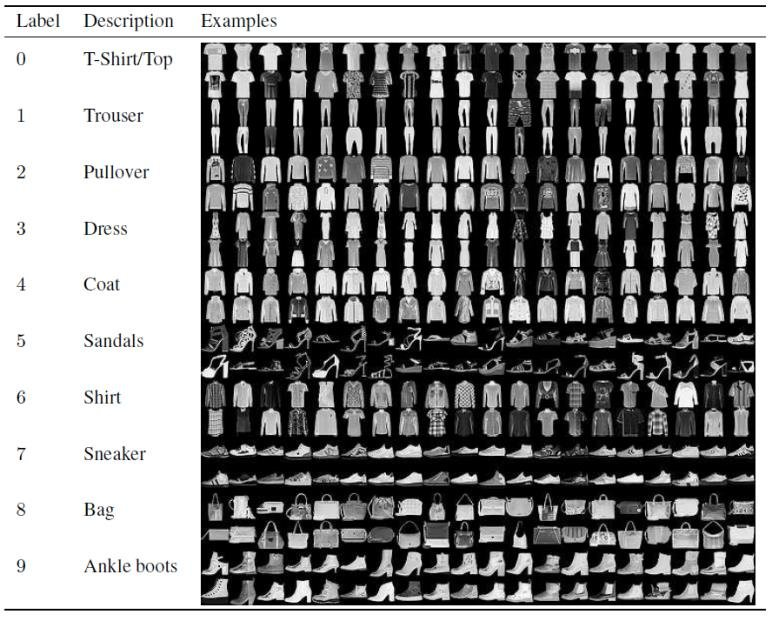

The data can be directly downloaded with PyTorch. Please visit the following website: https://pytorch.org/vision/stable/datasets.html

In [6]:
import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor

Download training (argument `train=True`) and test (argument `train=False`) data from open datasets. Don't forget to set the `transformation`. Please check [`Compose` module](https://docs.pytorch.org/vision/0.22/generated/torchvision.transforms.Compose.html).

In [7]:
FMNIST_data_train = torchvision.datasets.FashionMNIST('path/to/MNist_train/',train=True,
                                                      transform=torchvision.transforms.ToTensor(),
                                                     download=True)

FMNIST_data_test = torchvision.datasets.FashionMNIST('path/to/MNist_test/',train=False,
                                                      transform=torchvision.transforms.ToTensor(),
                                                     download=True)



Convert to dataloader. You can set a `batch_size` of 64.

In [8]:
trainloader = torch.utils.data.DataLoader(FMNIST_data_train,
                                          batch_size=64,
                                          shuffle=True)

testloader = torch.utils.data.DataLoader(FMNIST_data_test,
                                          batch_size=64,
                                          shuffle=True)

Visualize the data

images.shape: torch.Size([64, 1, 28, 28])


{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

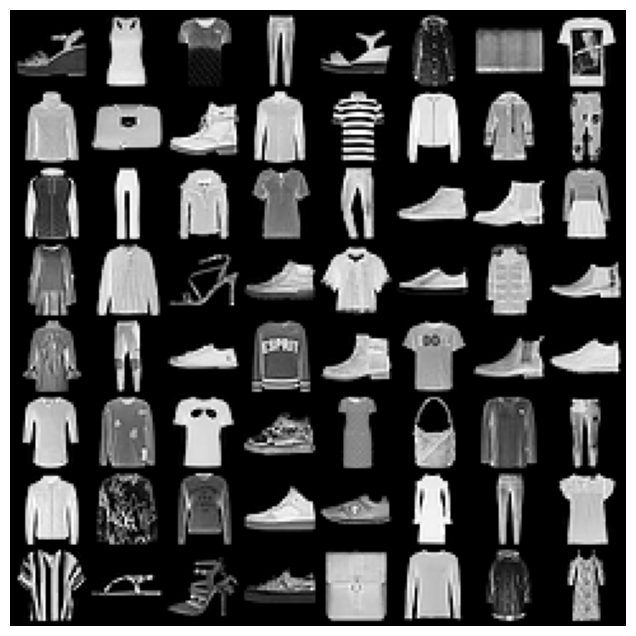

In [9]:
from torchvision.utils import make_grid
for images, _ in testloader:
    print('images.shape:', images.shape)
    plt.figure(figsize=(8,8))
    plt.axis('off')
    plt.imshow(make_grid(images, nrow=8).permute((1, 2, 0)))
    break
    
FMNIST_data_test.class_to_idx

### 3. Implement and train a fully-connected NN model with 2 hidden layers

Help:

- check all possible methods to set your network architecture: https://pytorch.org/docs/stable/nn.html
  - [Flatten](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html#torch.nn.Flatten)
  - [Linear](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html)
  - [ReLU](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html#torch.nn.ReLU)
  - [Softmax](https://pytorch.org/docs/stable/generated/torch.nn.Softmax.html#torch.nn.Softmax)
  - [CrossEntropyLoss](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html#torch.nn.CrossEntropyLoss)
- check various optimization algorithms: https://pytorch.org/docs/stable/optim.html


In [10]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super(Net,self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28*28, 256)
        self.fc2 = nn.Linear(256,128)
        self.fc3 = nn.Linear(128,10)
        
    def forward(self, x):
        x = self.flatten(x)
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        y = self.fc3(h2)
        return y

Initialize the model

In [11]:
model = Net().to(device)

Set the loss function and the optimizer

In [12]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
output_fn = nn.Softmax(dim=1)
optimizer = optimizer = optim.SGD(model.parameters(), lr=0.001)

Set the training loop and launch the training

In [13]:
N_EPOCHS = 10
for epoch in np.arange(N_EPOCHS):
    for idx,batch in enumerate(trainloader): #training loop
        # get the inputs; batch is a list of [inputs, labels]
        inputs,labels=batch
        inputs=inputs.to(device) #train on GPU
        labels=labels.to(device)
        # zero the parameter gradients
        optimizer.zero_grad()
        # forward + backward + optimize
        out = model(x=inputs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()

Evaluate on the test set

In [14]:
import torchmetrics
from torchmetrics.classification import Accuracy

# Initialize the metric for 10 classes and place it on the active device.
accuracy_metric = Accuracy(task="multiclass", num_classes=10).to(device)

# Set model to evaluation mode.
model.eval()

# Disable gradient calculation for evaluation.
with torch.no_grad():
  for inputs, labels in testloader:
    # Transfer batch data to the target device.
    inputs, labels = inputs.to(device), labels.to(device)

    # Compute model predictions.
    outputs = model(inputs)
    predictions = outputs.argmax(dim=1)

    # Accumulate metrics across batches.
    accuracy_metric.update(predictions, labels)

# Compute the final accuracy over the full test dataset.
total_accuracy = accuracy_metric.compute()
print(f"Accuracy on test set: {total_accuracy.item() * 100:.2f}%")

# Reset internal state if you plan to reuse the metric across epochs.
accuracy_metric.reset()

Accuracy on test set: 68.21%


#### Steps further

1. Monitor your training using a validation set
  - define a validation set
  - use it to evaluate the model at each epoch
  - only evaluate on the test set at the end of the training

2. Try to change the optimizer 


How to save the model? <br>
Help: https://pytorch.org/tutorials/beginner/saving_loading_models.html


### 4. Implement and train a LeNet model

Help:
- [Conv2d](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)
- [AvgPool2d](https://pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html#torch.nn.AvgPool2d)


In [19]:
import torch.nn as nn
import torch.nn.functional as F

class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        # First convolutional layer: 1 input channel (grayscale), 6 output channels, 5x5 square convolution kernel.
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5)
        # pool of square window of size=3, stride=2
        self.pool1 = nn.AvgPool2d(3, stride=2)
        self.fc3 = nn.Linear(128,10)

    def forward(self, x):
        h1 = F.relu(self.pool1(x))
        h2 = F.relu(self.conv1(h1))
        y = self.fc3(h2)

Set the criterion and the optimizer

In [21]:
model1 = LeNet().to(device)

criterion = nn.CrossEntropyLoss()
output_fn = nn.Softmax(dim=1)
optimizer = optimizer = optim.SGD(model.parameters(), lr=0.001)

Launch the training

In [22]:
N_EPOCHS = 10
for epoch in np.arange(N_EPOCHS):
    for idx,batch in enumerate(trainloader): #training loop
        # get the inputs; batch is a list of [inputs, labels]
        inputs,labels=batch
        inputs=inputs.to(device) #train on GPU
        labels=labels.to(device)
        # zero the parameter gradients
        optimizer.zero_grad()
        # forward + backward + optimize
        out = model1(x=inputs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()

RuntimeError: mat1 and mat2 shapes cannot be multiplied (3456x9 and 128x10)

Set the training loop

#### Steps further

1. Modernize LeNet. Implement and test the following changes:
- Replace average pooling with max-pooling.
- Replace the softmax layer with ReLU.

2. Compare CNN and MLP

| Model | Parameters | Validation accuracy | Test accuracy | Training time |
| ----- | ---------: | ------------------: | ------------: | ------------: |
| MLP   |            |                     |               |               |
| CNN   |            |                     |               |               |

By drawing the confusion matrix,
- which classes are the hardest to distinguish?
- are the errors made by the MLP and the CNN of the same nature?
- does the CNN improve performance across all classes uniformly?

3. Try to change the size of the LeNet style network to improve its accuracy in addition to max-pooling and ReLU. You could for example adjust:
- the convolution window size;
- the number of output channels;
- the number of convolution layers;
- the number of fully connected layers;
- the learning rates and other training details (e.g., initialization and number of epochs).

From: http://d2l.ai/chapter_convolutional-neural-networks/lenet.html